# Processamento de Sinais II — Lista 1
Solução usando OpenCV, NumPy e Matplotlib. Execute as células na ordem.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
REPO = HERE if (HERE / 'data').exists() else HERE.parent
# O dataset já está disponível na pasta data/dataset do repositório.
DATA = REPO / 'data' / 'dataset'

def ler(nome, cinza=False):
    modo = cv2.IMREAD_GRAYSCALE if cinza else cv2.IMREAD_COLOR
    imagem = cv2.imread(str(DATA / nome), modo)
    if imagem is None: raise FileNotFoundError(nome)
    return imagem

def mostrar(imagens, colunas=4, tamanho=(4, 4)):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=(tamanho[0] * colunas, tamanho[1] * linhas), squeeze=False)
    axs = axs.ravel()
    for ax, (titulo, imagem) in zip(axs, imagens):
        if imagem.ndim == 3: imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
        ax.imshow(imagem, cmap='gray')
        ax.set_title(titulo); ax.axis('off')
    for ax in axs[len(imagens):]: ax.axis('off')
    plt.tight_layout(); plt.show()

lena = ler('lena2.tif', True)
lena_colorida = ler('lena3.tif')
frog = ler('frog.tif', True)
brain = ler('brain.jpg', True)

Este bloco prepara o dataset e cria funções auxiliares para carregar e exibir as imagens. Assim, o código das questões fica menor e mais fácil de acompanhar.

## 1) A imagem original da Lena gray possui resolução 512 x 512 pixels. Decime essa imagem para 256 x 256, 128 x 128 e 64 x 64. Exiba as imagens lado a lado e do mesmo tamanho que a imagem original.

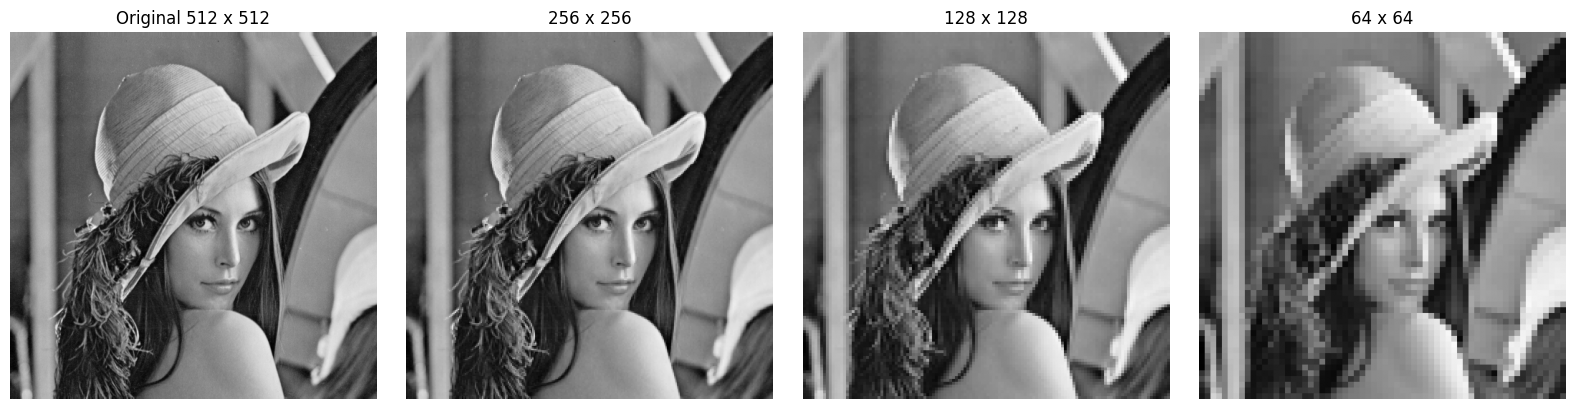

In [2]:
reduzidas = []
for lado in [256, 128, 64]:
    pequena = cv2.resize(lena, (lado, lado), interpolation=cv2.INTER_AREA)
    de_volta = cv2.resize(pequena, (512, 512), interpolation=cv2.INTER_NEAREST)
    reduzidas.append((f'{lado} x {lado}', de_volta))
mostrar([('Original 512 x 512', lena)] + reduzidas)

A redução diminui a quantidade de amostras espaciais. A interpolação `INTER_AREA` reduz aliasing, mas os detalhes menores que a nova resolução são perdidos.

## 2) Exiba os canais da Lena color. Explique por que cada canal é exibido em níveis de cinza embora representem as componentes R, G e B.

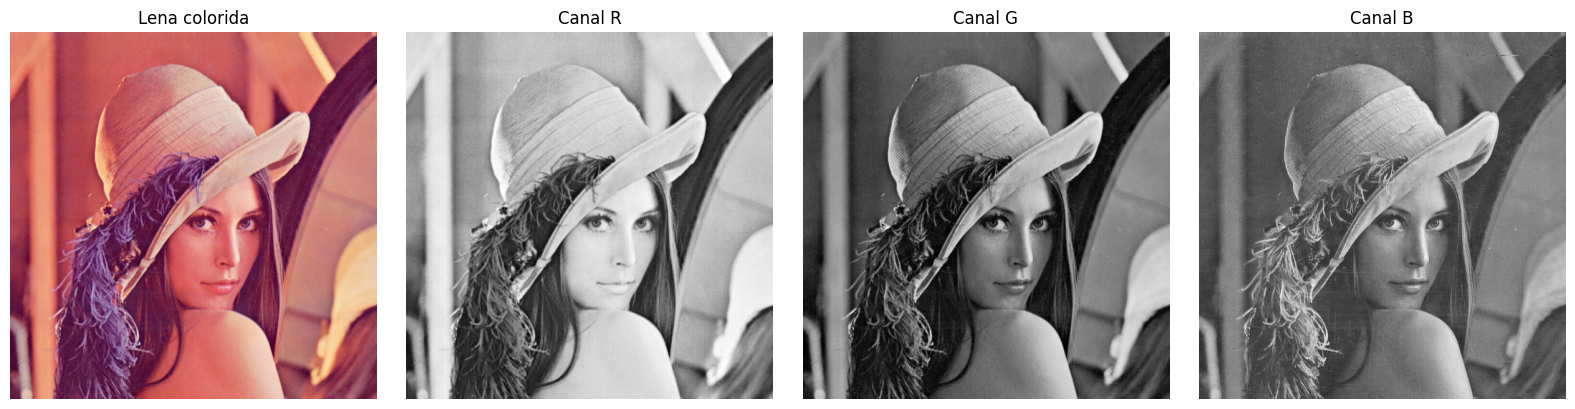

In [3]:
b, g, r = cv2.split(lena_colorida)
mostrar([('Lena colorida', lena_colorida), ('Canal R', r), ('Canal G', g), ('Canal B', b)])

Cada canal é uma matriz de intensidade. O nível de cinza representa a quantidade daquela componente em cada pixel; os três canais juntos formam a imagem colorida. O OpenCV lê a imagem na ordem BGR.

## 3) Quantos bits por pixel temos na Lena color e quantos na Lena gray? Quantize a Lena gray com 6, 4, 2 e 1 bit por pixel. Exiba a imagem original e versões quantizadas lado a lado e comente os resultados.

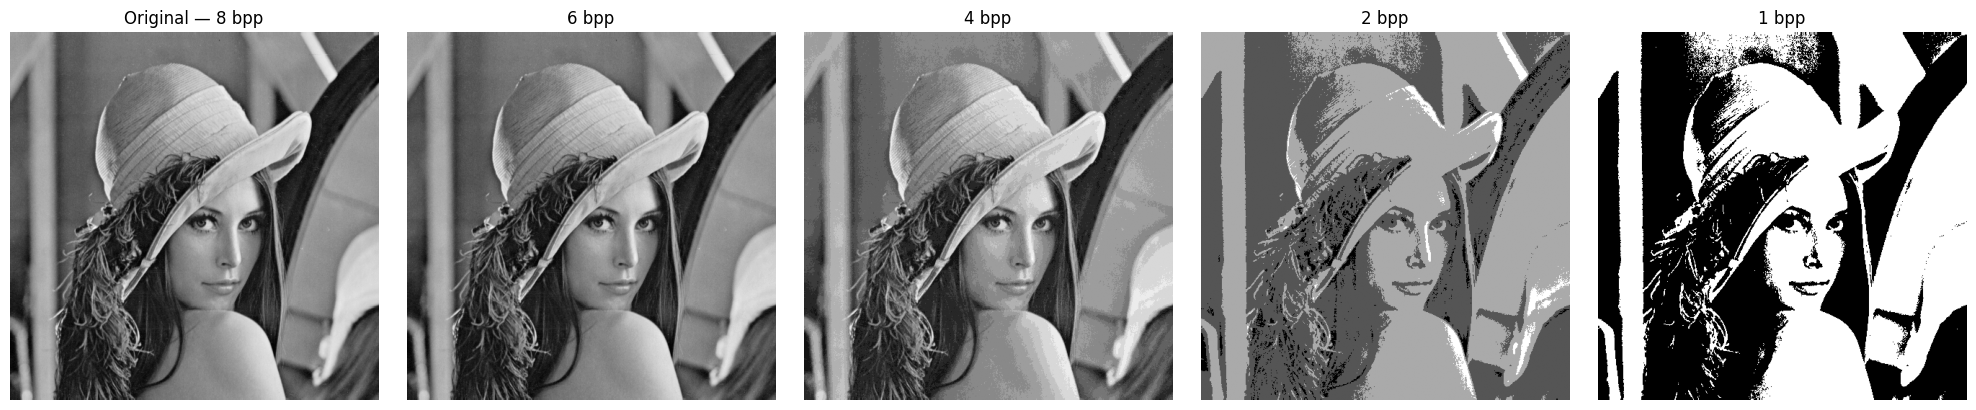

In [4]:
def quantizar(imagem, bits):
    niveis = 2 ** bits
    passo = 255 / (niveis - 1)
    return np.uint8(np.round(imagem / passo) * passo)
mostrar([('Original — 8 bpp', lena)] + [(f'{bits} bpp', quantizar(lena, bits)) for bits in [6, 4, 2, 1]], colunas=5)

A Lena color possui 24 bits por pixel, pois são 8 bits para cada canal RGB. A Lena gray possui 8 bits por pixel. Com menos bits, há menos níveis de cinza e aparecem regiões com o mesmo tom, chamadas de banding ou contouring.

## 4) Crie uma imagem sintética cinza (resolução 256 x 256 pixels) com nível 128. Crie um quadrado (32x32 pixels) no centro e aumente o nível de cinza desse quadrado até que ele esteja no limite da percepção. Repita o processo diminuindo o nível de cinza do quadrado central. Explique a ilusão de óptica.

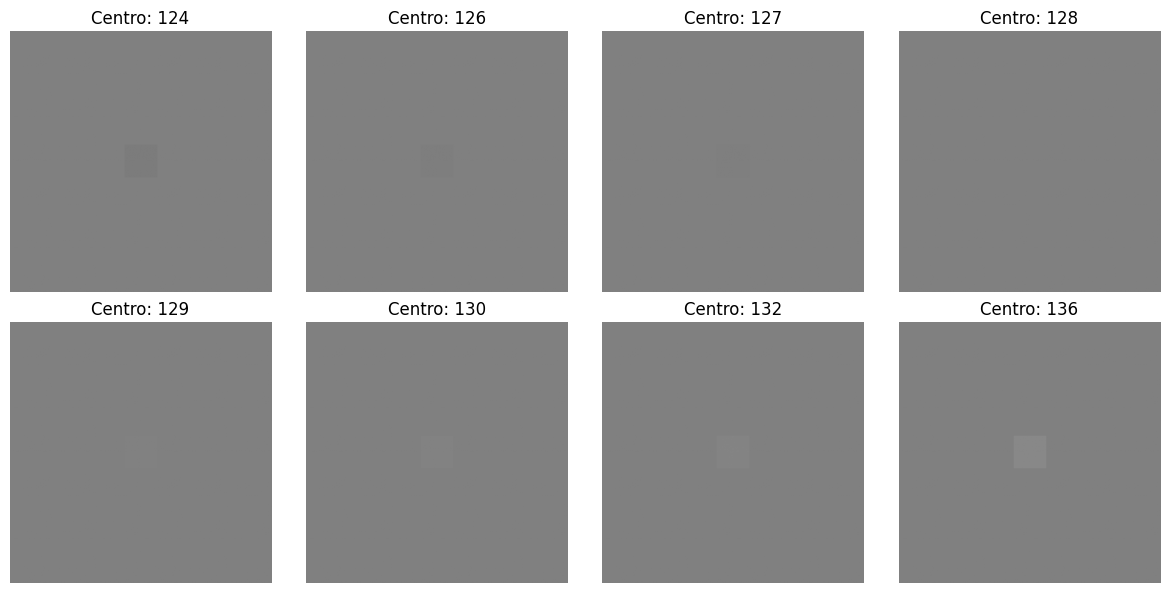

In [5]:
fundo = np.full((256, 256), 128, np.uint8)
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for ax, valor in zip(axs[0], [124, 126, 127, 128]):
    imagem = fundo.copy(); imagem[112:144, 112:144] = valor
    ax.imshow(imagem, cmap='gray', vmin=0, vmax=255); ax.set_title(f'Centro: {valor}'); ax.axis('off')
for ax, valor in zip(axs[1], [129, 130, 132, 136]):
    imagem = fundo.copy(); imagem[112:144, 112:144] = valor
    ax.imshow(imagem, cmap='gray', vmin=0, vmax=255); ax.set_title(f'Centro: {valor}'); ax.axis('off')
plt.tight_layout(); plt.show()

A Lei de Weber relaciona a menor diferença perceptível à razão ΔI/I. Por isso diferenças pequenas podem ser percebidas em um fundo e desaparecer em outro. A Lei de Fechner explica a aproximação logarítmica da percepção humana de luminância.

## 5) Considere a imagem Frog. Aplique um ajuste de brilho a partir do escalonamento da intensidade. Use um ajuste na escala de 1.2. Exiba as imagens lado a lado e comente os resultados.

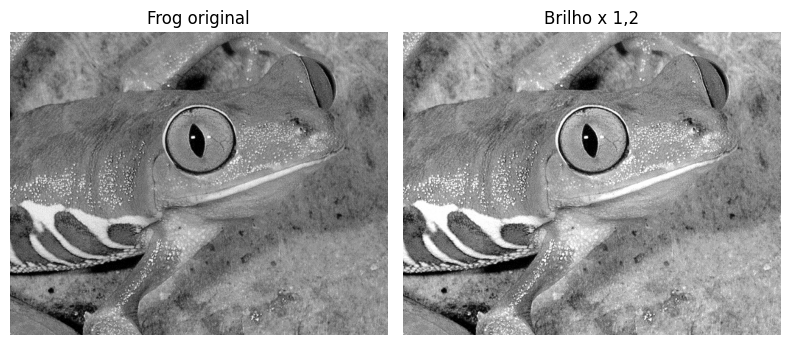

In [6]:
brilho = cv2.convertScaleAbs(frog, alpha=1.2, beta=0)
mostrar([('Frog original', frog), ('Brilho x 1,2', brilho)], colunas=2)

O fator 1,2 aumenta as intensidades. Os pixels que ultrapassariam 255 são saturados no valor máximo, podendo causar perda de detalhes nas regiões claras.

## 6) Considere a imagem Frog. Aplique um ajuste de contraste a partir da modificação do gamma. Use gamma = 1.5. Exiba as imagens lado a lado e comente os resultados.

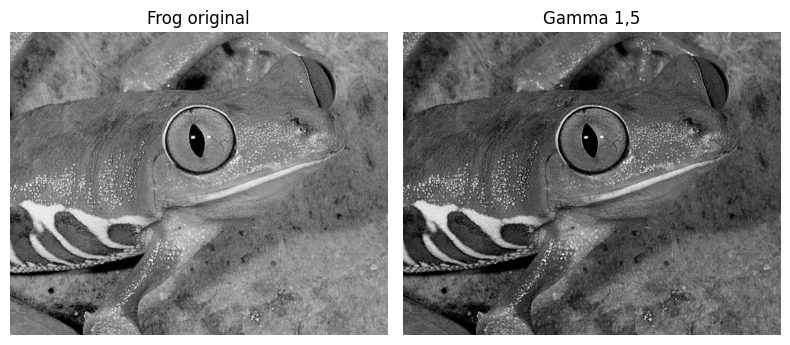

In [7]:
tabela_gamma = np.array([((i / 255.0) ** 1.5) * 255 for i in range(256)], dtype=np.uint8)
gamma = cv2.LUT(frog, tabela_gamma)
mostrar([('Frog original', frog), ('Gamma 1,5', gamma)], colunas=2)

Foi usada a convenção s = r^gamma, coerente com a característica de gamma apresentada nos slides. Como gamma é maior que 1, as diferenças nos tons escuros são comprimidas e as diferenças nos tons claros são mais destacadas, alterando o contraste.

## 7) Crie 32 imagens com ruído gaussiano a partir da imagem Brain. Aplique a técnica de supressão de ruído a partir da média das imagens. Compare com a imagem original.

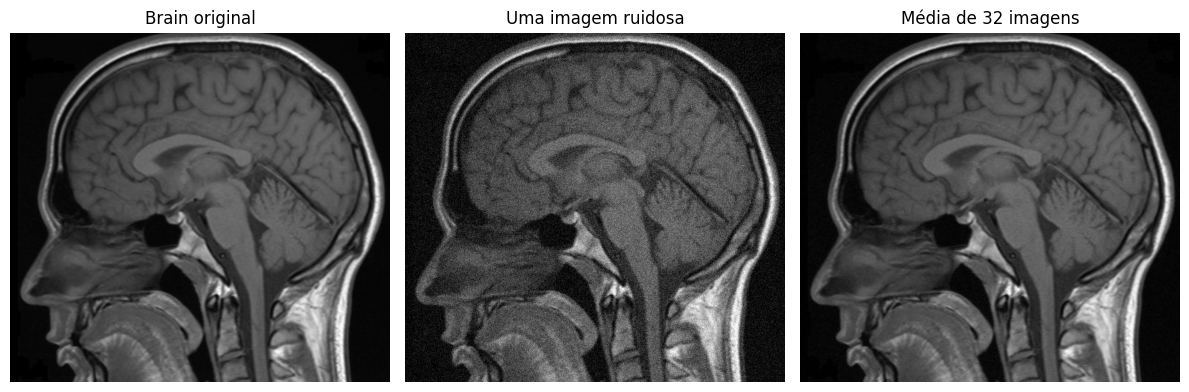

In [8]:
np.random.seed(7)
imagens_ruidosas = []
for _ in range(32):
    ruido = np.random.normal(0, 25, brain.shape)
    imagens_ruidosas.append(brain.astype(float) + ruido)
media = np.mean(imagens_ruidosas, axis=0)
mostrar([('Brain original', brain), ('Uma imagem ruidosa', np.uint8(np.clip(imagens_ruidosas[0], 0, 255))), ('Média de 32 imagens', np.uint8(np.clip(media, 0, 255)))], colunas=3)

Como o ruído é aleatório e tem média próxima de zero, ele tende a se cancelar na média. O resultado fica mais próximo da imagem original e o desvio do ruído diminui aproximadamente por √32.

## 8) Calcule e exiba os histogramas das imagens Lena gray, Moon, Bay e Brain. Relacione o formato dos histogramas com as características das imagens.

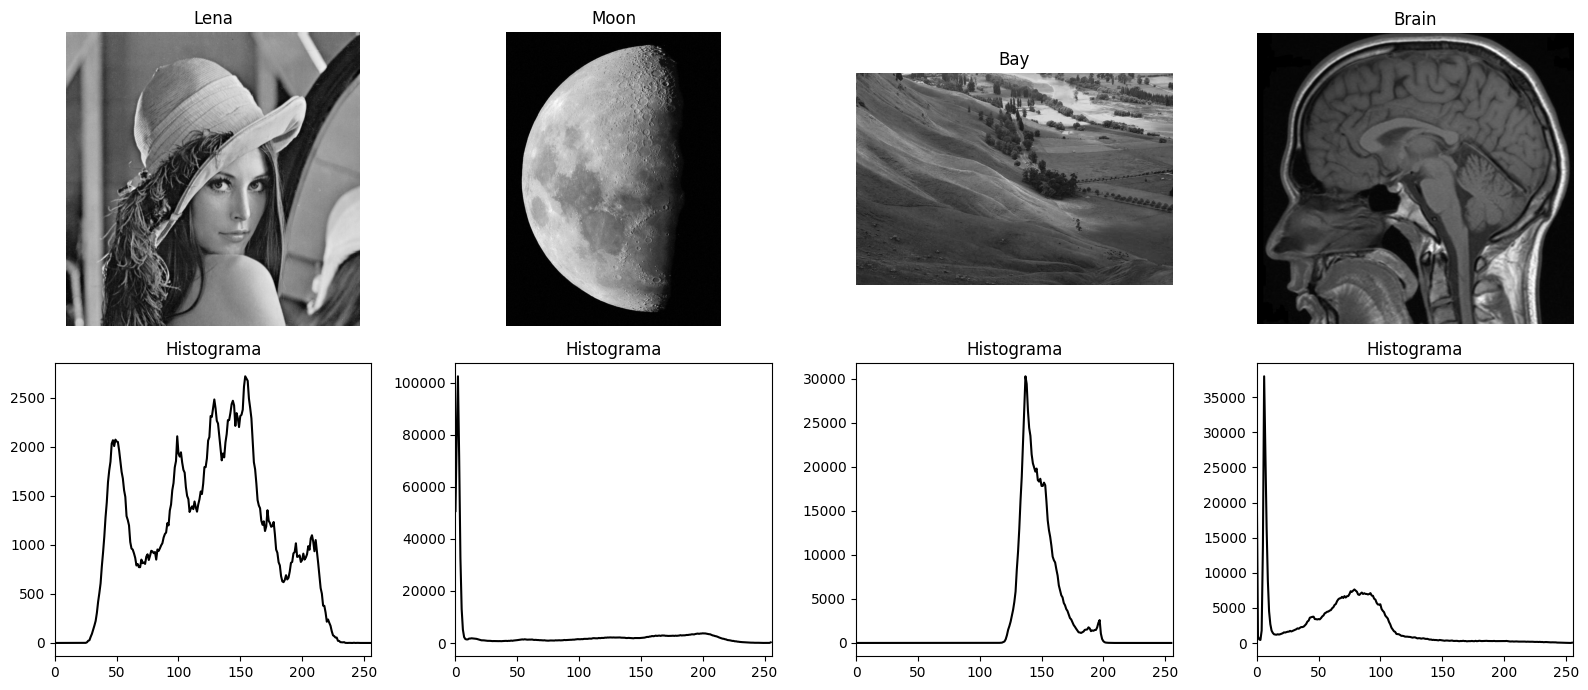

In [9]:
imagens = {'Lena': lena, 'Moon': ler('moon.jpg', True), 'Bay': ler('bay.jpg', True), 'Brain': brain}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for coluna, (nome, imagem) in enumerate(imagens.items()):
    axs[0, coluna].imshow(imagem, cmap='gray'); axs[0, coluna].set_title(nome); axs[0, coluna].axis('off')
    hist = cv2.calcHist([imagem], [0], None, [256], [0, 256])
    axs[1, coluna].plot(hist, color='black'); axs[1, coluna].set_xlim(0, 256); axs[1, coluna].set_title('Histograma')
plt.tight_layout(); plt.show()

Na Lena, os tons ficam distribuídos por uma faixa ampla por causa do cabelo, pele e fundo. Na Moon e na Brain aparece um pico forte próximo de zero, associado ao fundo escuro. A Bay ocupa uma faixa mais estreita de níveis, indicando menor contraste.

## 9) Aplique a equalização de histogramas nas imagens Lena gray, Moon, Bay e Brain. Compare o resultado com as imagens originais.

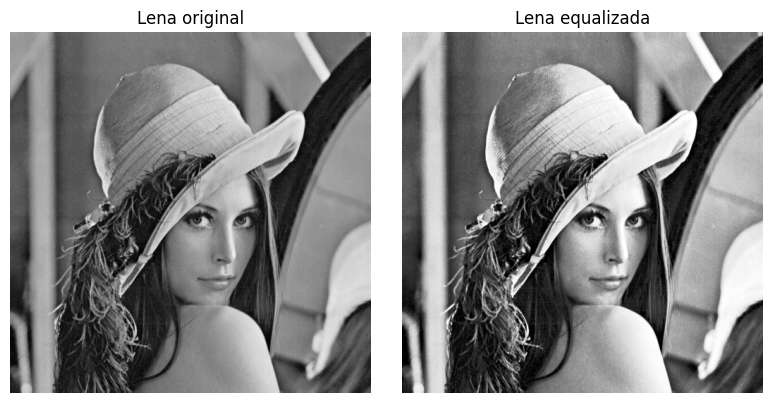

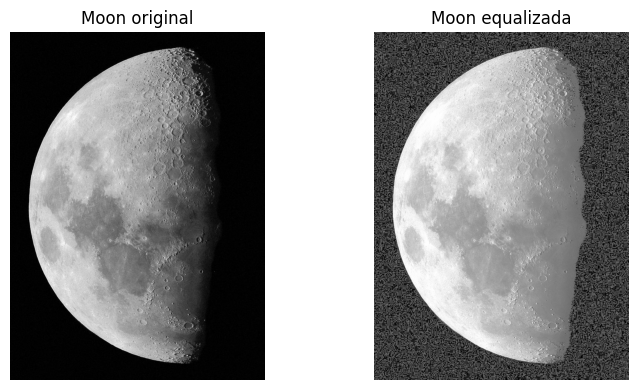

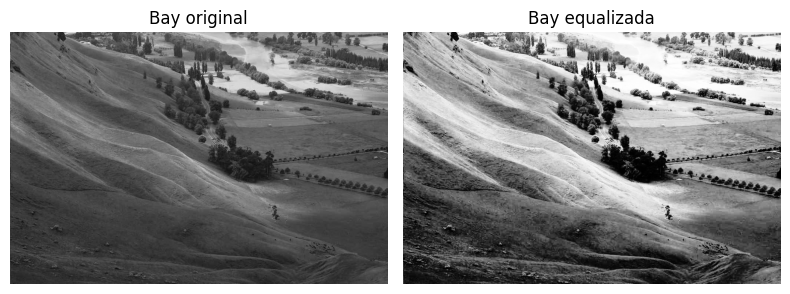

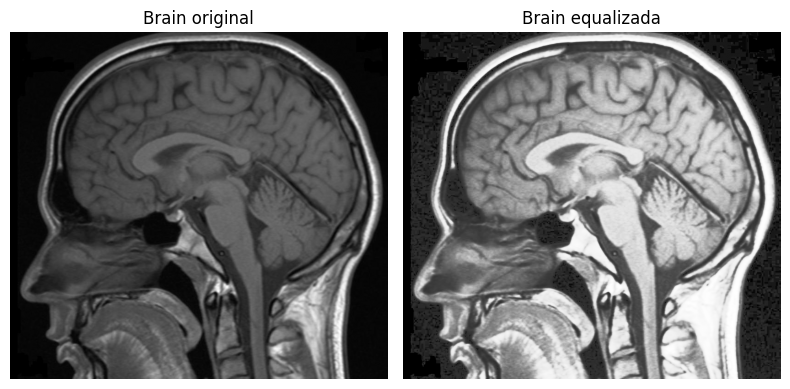

In [10]:
globais = {nome: cv2.equalizeHist(imagem) for nome, imagem in imagens.items()}
for nome in imagens:
    mostrar([(f'{nome} original', imagens[nome]), (f'{nome} equalizada', globais[nome])], colunas=2)

Na Lena, a equalização aumenta a separação entre regiões claras e escuras. Na Moon e na Brain, o fundo escuro continua dominante, mas os detalhes das regiões não pretas ficam mais visíveis. Na Bay, a faixa estreita original é expandida e o contraste aumenta, principalmente nas áreas que antes tinham tons parecidos.

## 10) Aplique a equalização adaptativa de histogramas nas imagens Lena gray, Moon, Bay e Brain. Utilize blocos de tamanho 8x8 e 16x16 pixels. Compare os resultados com o que foi obtido na Questão 9.

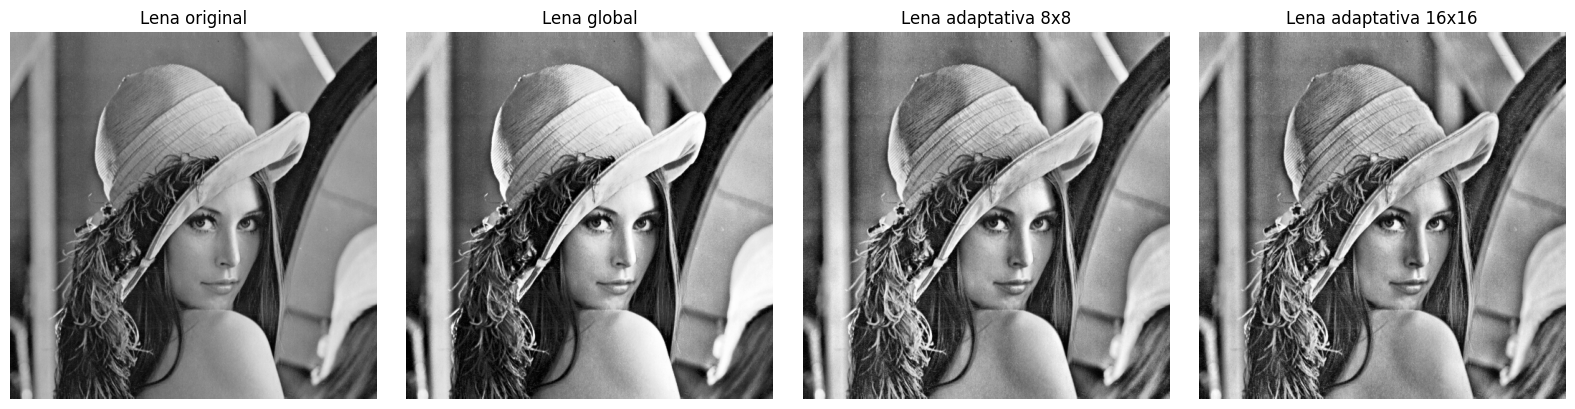

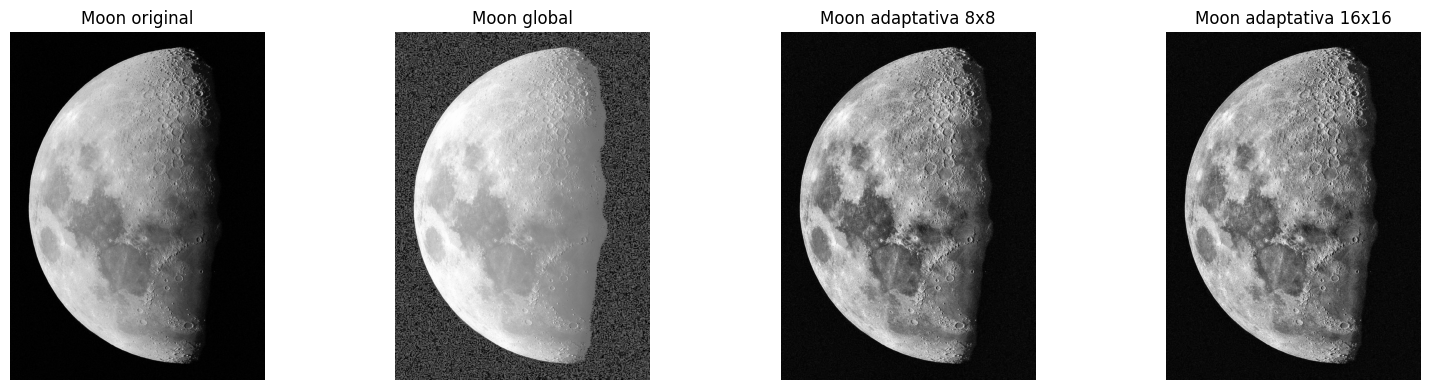

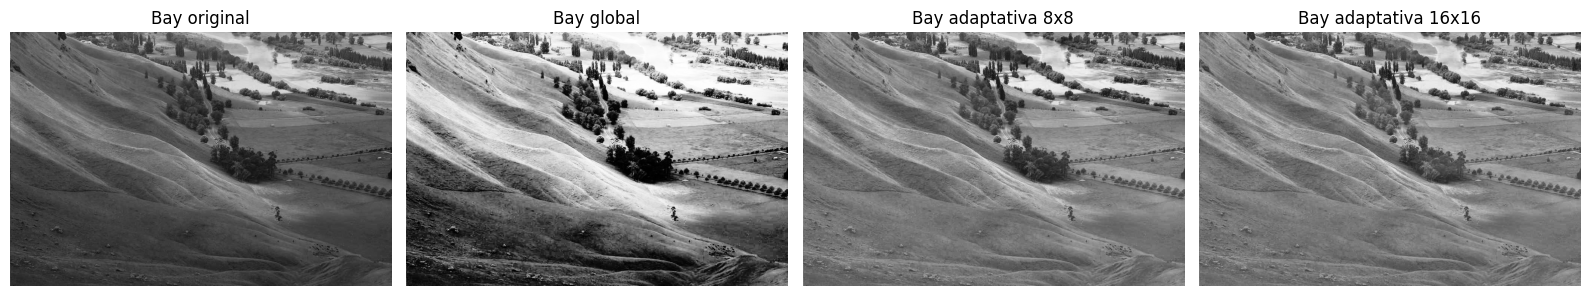

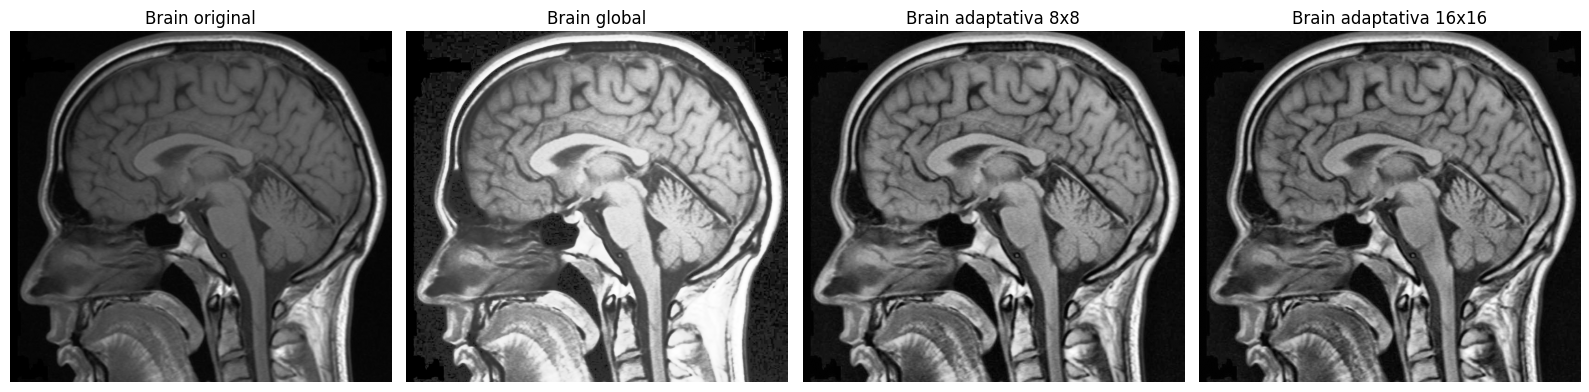

In [11]:
clahe8 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe16 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
for nome in imagens:
    adaptada8 = clahe8.apply(imagens[nome])
    adaptada16 = clahe16.apply(imagens[nome])
    mostrar([(f'{nome} original', imagens[nome]), (f'{nome} global', globais[nome]), (f'{nome} adaptativa 8x8', adaptada8), (f'{nome} adaptativa 16x16', adaptada16)], colunas=4)

Comparando com a Q9, a equalização adaptativa recupera detalhes em regiões diferentes da mesma imagem. Na Moon e na Brain ela melhora áreas escuras localmente; na Bay evita depender de um único histograma global. O bloco 8x8 realça mais detalhes e pode aumentar ruído, enquanto 16x16 é mais suave. No OpenCV, `tileGridSize` define a quantidade de blocos em cada direção.

## 11) Exiba a imagem Balloons lado a lado com os seus canais R, G e B. Os canais devem ser exibidos como imagens monocromáticas. Explique.

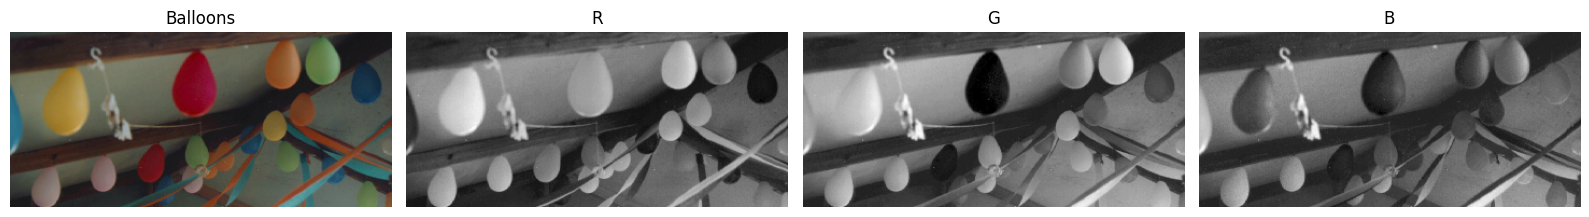

In [12]:
balloons = ler('balloons.tif')
b, g, r = cv2.split(balloons)
mostrar([('Balloons', balloons), ('R', r), ('G', g), ('B', b)])

Cada canal representa a intensidade de uma componente da cor. Balões vermelhos ficam mais claros no canal R, balões verdes no canal G e balões azuis no canal B. A representação monocromática é usada porque cada canal é uma imagem escalar, não uma imagem RGB completa.

## 12) Converta a imagem Balloons para níveis de cinza a partir da média dos canais. Em seguida converta utilizando a função de conversão padrão. Exiba as imagens lado a lado e explique por que elas são diferentes.

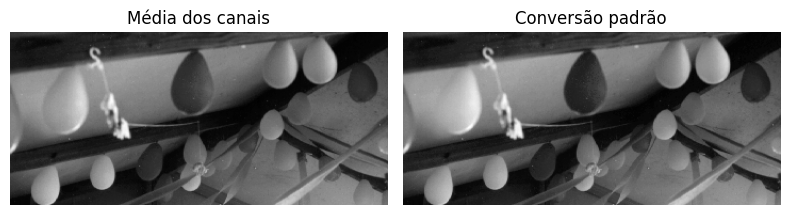

In [13]:
media_cinza = np.uint8(np.mean(balloons, axis=2))
cinza_padrao = cv2.cvtColor(balloons, cv2.COLOR_BGR2GRAY)
mostrar([('Média dos canais', media_cinza), ('Conversão padrão', cinza_padrao)], colunas=2)

A média atribui o mesmo peso a R, G e B. A conversão padrão do OpenCV usa pesos diferentes, dando maior importância ao verde porque a visão humana é mais sensível a essa região do espectro.

## 13) Converta a imagem Peppers_color para níveis de cinza. Aplique uma binarização por limiar global para destacar apenas a cor vermelha. Em seguida, use a imagem binária como máscara e aplique na imagem original. Explique as imperfeições.

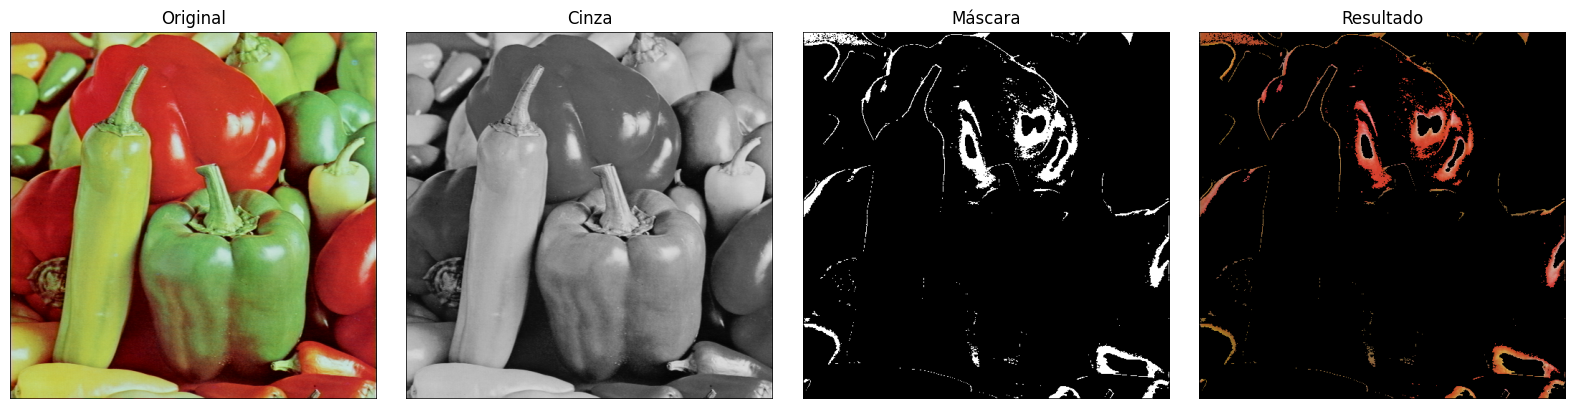

In [14]:
peppers = ler('peppers3.tif')
cinza = cv2.cvtColor(peppers, cv2.COLOR_BGR2GRAY)
_, limiar = cv2.threshold(cinza, 100, 255, cv2.THRESH_BINARY)
b, g, r = cv2.split(peppers)
vermelho = ((r > g * 1.25) & (r > b * 1.25) & (limiar > 0)).astype(np.uint8) * 255
resultado = cv2.bitwise_and(peppers, peppers, mask=vermelho)
mostrar([('Original', peppers), ('Cinza', cinza), ('Máscara', vermelho), ('Resultado', resultado)])

O cinza sozinho não identifica a cor: cores diferentes podem ter a mesma luminância, pois a conversão perde a informação de matiz. Por isso a máscara também compara o canal R com G e B. Os erros aparecem principalmente em sombras, reflexos e regiões alaranjadas, que podem passar ou ser removidas indevidamente.

## 14) Converta a imagem Guia para níveis de cinza e aplique o Otsu global. Em seguida, aplique a binarização localmente adaptativa. Use a variância como medida de uniformidade. Qual é o tamanho de janela que acarreta em melhor resultado?

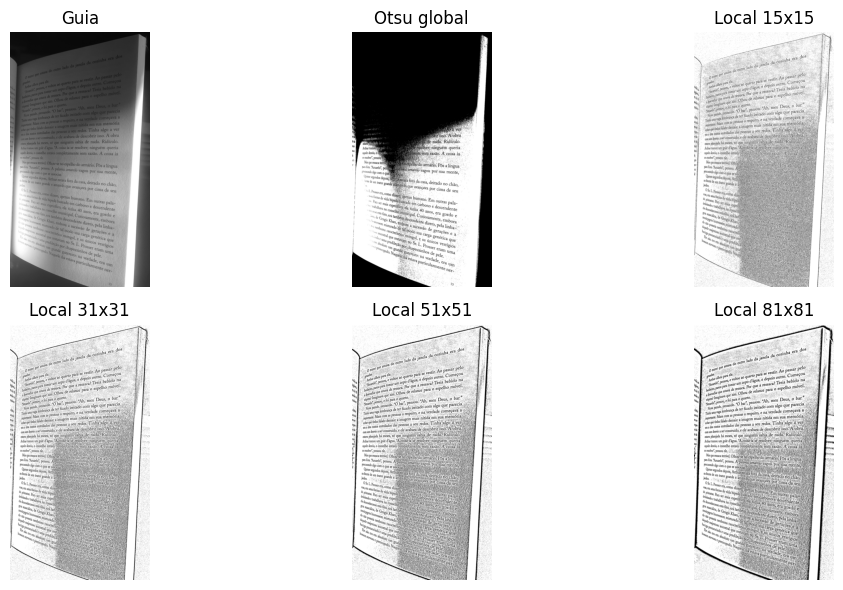

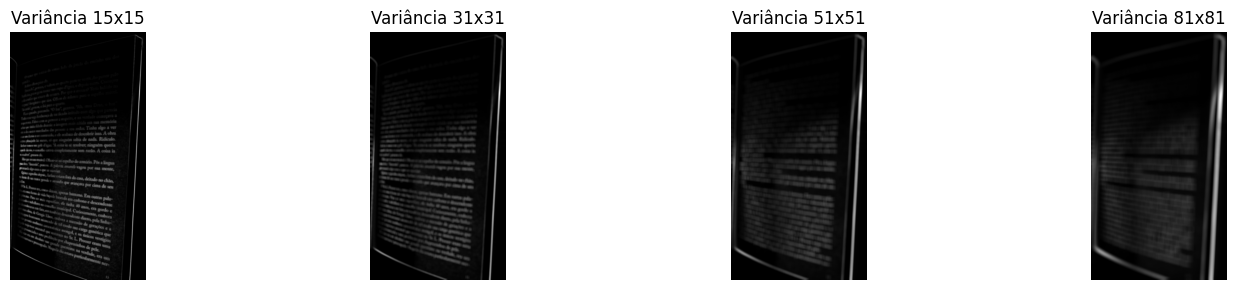

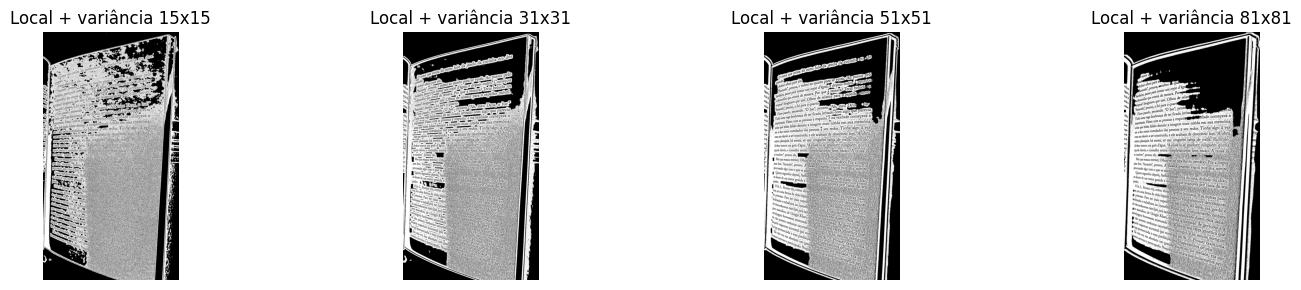

In [15]:
guia = cv2.cvtColor(ler('guia.jpg'), cv2.COLOR_BGR2GRAY)
_, otsu = cv2.threshold(guia, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
locais = []
variancias = []
resultados_com_variancia = []
for janela in [15, 31, 51, 81]:
    local = cv2.adaptiveThreshold(guia, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, janela, 5)
    valores = guia.astype(np.float32)
    media_local = cv2.blur(valores, (janela, janela))
    media_quadratica = cv2.blur(valores ** 2, (janela, janela))
    variancia = np.maximum(media_quadratica - media_local ** 2, 0)
    limite_variancia = np.percentile(variancia, 30)
    regioes_com_texto = np.uint8(variancia > limite_variancia) * 255
    resultado = cv2.bitwise_and(local, regioes_com_texto)
    locais.append((f'Local {janela}x{janela}', local))
    variancias.append((f'Variância {janela}x{janela}', variancia))
    resultados_com_variancia.append((f'Local + variância {janela}x{janela}', resultado))
mostrar([('Guia', guia), ('Otsu global', otsu)] + locais, colunas=3, tamanho=(4, 3))
mostrar(variancias, colunas=4, tamanho=(4, 3))
mostrar(resultados_com_variancia, colunas=4, tamanho=(4, 3))

A variância baixa indica regiões uniformes; a variância alta indica texto ou bordas. O limiar de variância separa as regiões com informação do fundo uniforme e entra na máscara final. Comparando as janelas, 31x31 é um bom compromisso para a Guia: preserva os caracteres sem fragmentar tanto o fundo.